In [2]:
import matplotlib.pyplot as plt
import numpy as np
import os, glob
import pandas as pd
plt.style.use('properties.mplstyle')

In [3]:
df = pd.read_csv("/home/light/Documents/SpatialPreferential/processed/properties/all_data.csv")
df
#df = df_trash.dropna(axis=1)
#df


,N,m0,dim,alpha_a,alpha_g,N_samples,Short_Cost_mean,Short_Cost_error,Short_BFS_mean,Short_BFS_error,Short_BFS_sampled_1000_mean,Short_BFS_sampled_1000_error,R_Spearman_mean,R_Spearman_error,R_Newman_mean,R_Newman_error,ClusterCoefficient_mean,ClusterCoefficient_error
0,100000,2,1,0.0,1.0,100,NaN,NaN,NaN,NaN,5.902961,0.003779,NaN,NaN,-0.021125,0.000747,0.000724,0.000012
1,100000,2,1,0.0,2.0,100,NaN,NaN,NaN,NaN,5.904023,0.004120,NaN,NaN,-0.021552,0.000711,0.000709,0.000011
2,100000,2,1,0.0,3.0,100,NaN,NaN,NaN,NaN,5.903787,0.003519,NaN,NaN,-0.021153,0.000709,0.000720,0.000010
3,100000,2,1,0.0,4.0,100,NaN,NaN,NaN,NaN,5.899351,0.003671,NaN,NaN,-0.021000,0.000681,0.000717,0.000010
4,100000,2,1,0.0,5.0,100,NaN,NaN,NaN,NaN,5.903328,0.003538,NaN,NaN,-0.021145,0.000705,0.000723,0.000010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,100000,4,3,9.0,1.0,8,NaN,NaN,7.730129,0.098228,NaN,NaN,NaN,NaN,0.224255,0.003136,0.385274,0.000544
353,100000,4,3,9.0,3.0,8,NaN,NaN,7.689608,0.020512,NaN,NaN,NaN,NaN,0.230148,0.002982,0.394138,0.000136
354,100000,4,3,9.0,4.0,8,NaN,NaN,7.818458,0.015268,NaN,NaN,NaN,NaN,0.228685,0.002808,0.394955,0.000256
355,100000,4,3,9.0,5.0,8,NaN,NaN,7.957521,0.015091,NaN,NaN,NaN,NaN,0.225516,0.002573,0.396218,0.000254


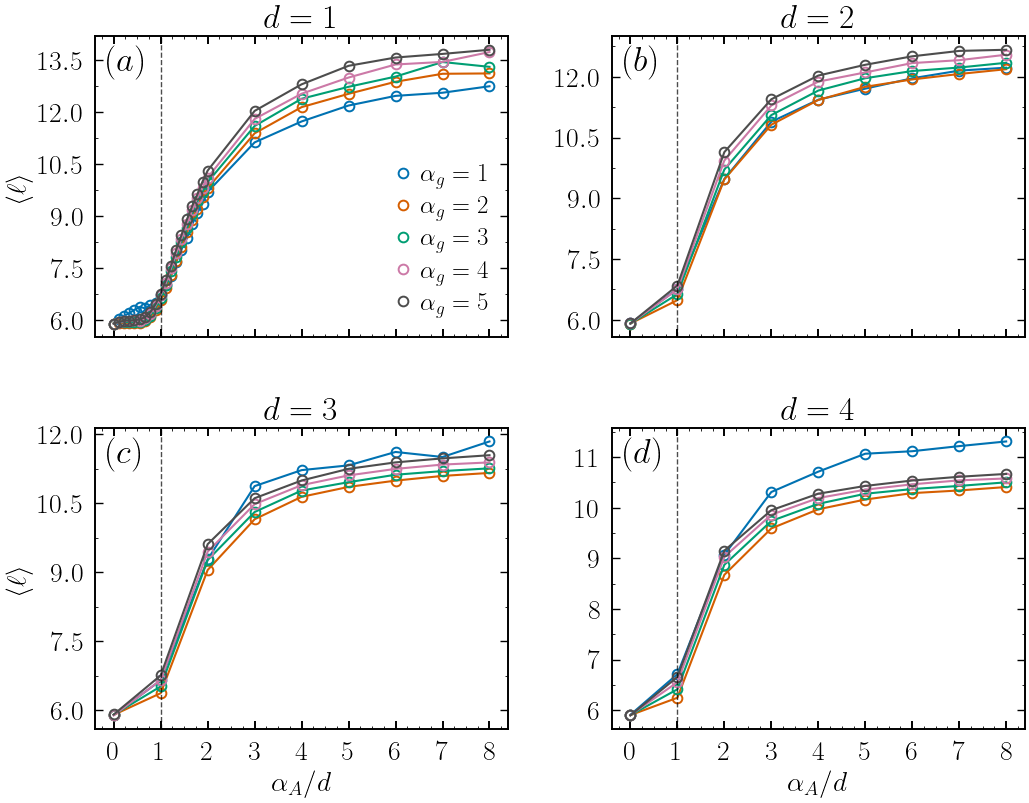

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, MaxNLocator
from matplotlib.lines import Line2D

N = 10**5
m0 = 2
alpha_g_lst = [1, 2, 3, 4, 5]
dim_lst = [1, 2, 3, 4]

mew = 1.4
ms = 7

colors = [
    '#0072B2',
    '#D55E00',
    '#009E73',
    '#CC79A7',
    '#4D4D4D',
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    sharey=False
)

for ax, dim in zip(axes.flat, dim_lst):

    for idx, alpha_g in enumerate(alpha_g_lst):

        df_sub = df[
            (df['N'] == N) &
            (df['m0'] == m0) &
            (df['alpha_g'] == alpha_g) &
            (df['dim'] == dim)
        ].sort_values(by='alpha_a')

        alpha_a_D = df_sub['alpha_a'].to_numpy() / dim
        short = df_sub['Short_BFS_sampled_1000_mean'].to_numpy()

        ax.plot(
            alpha_a_D, short,
            marker='o',
            ms=ms,
            mew=mew,
            mfc='none',
            mec=colors[idx],
            color=colors[idx],
            label=rf'$\alpha_g={alpha_g}$'
        )

    # Título com a dimensão
    ax.set_title(rf'$d={dim}$')

    # Ticks do eixo x
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.xaxis.set_minor_locator(MultipleLocator(0.25))

    # Ticks do eixo y
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.tick_params(
        axis='both',
        which='major',
        direction='in',
        top=True,
        right=True
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='in',
        top=True,
        right=True
    )
    ax.axvline(
        x=1,
        color='black',
        linestyle='--',
        linewidth=1.0,
        alpha=0.7
    )
for ax, label in zip(axes.flat, [r'$(a)$', r'$(b)$', r'$(c)$', r'$(d)$']):
    ax.text(
        0.03, 0.97,
        label,
        transform=ax.transAxes,
        fontsize=25,
        fontweight='bold',
        ha='left',
        va='top'
    )
# Labels apenas na linha inferior
for ax in axes[-1, :]:
    ax.set_xlabel(r'$\alpha_A / d$')

# Labels apenas na coluna esquerda
for ax in axes[:, 0]:
    ax.set_ylabel(r'$\langle \ell \rangle$')

# Legenda contendo apenas marcadores
legend_handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=colors[idx],
        markeredgewidth=mew,
        markersize=ms,
        label=rf'$\alpha_g={alpha_g}$'
    )
    for idx, alpha_g in enumerate(alpha_g_lst)
]

axes[0, 0].legend(
    handles=legend_handles,
    loc='best',
    frameon=False,
    fontsize=18,
    handlelength=0.8,
    handletextpad=0.3,
    labelspacing=0.3,
    borderaxespad=0.4,
    alignment='center'
)

fig.subplots_adjust(
    wspace=0.25,
    hspace=0.30
)
plt.savefig("../../results/short_bfs_vs_alpha_a.pdf", bbox_inches='tight', dpi=300)
plt.show()

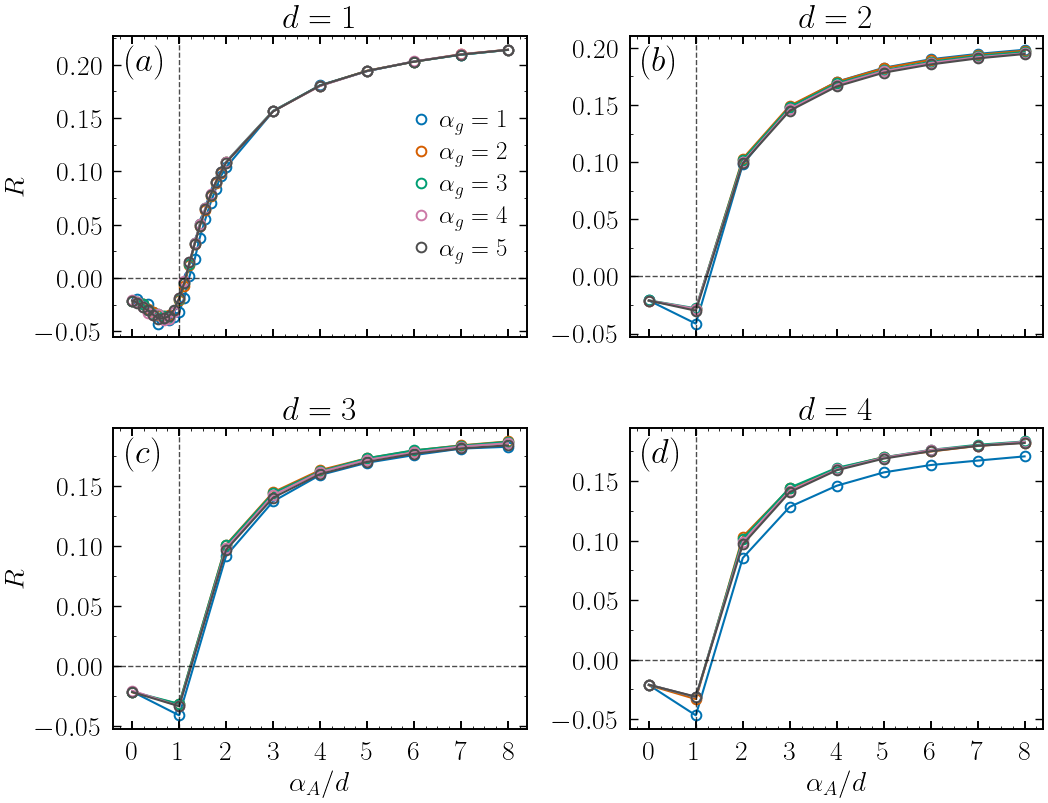

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, MaxNLocator
from matplotlib.lines import Line2D

N = 10**5
m0 = 2
alpha_g_lst = [1, 2, 3, 4, 5]
dim_lst = [1, 2, 3, 4]

mew = 1.4
ms = 7

colors = [
    '#0072B2',
    '#D55E00',
    '#009E73',
    '#CC79A7',
    '#4D4D4D',
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    sharey=False
)

for ax, dim in zip(axes.flat, dim_lst):

    for idx, alpha_g in enumerate(alpha_g_lst):

        df_sub = df[
            (df['N'] == N) &
            (df['m0'] == m0) &
            (df['alpha_g'] == alpha_g) &
            (df['dim'] == dim)
        ].sort_values(by='alpha_a')

        alpha_a_D = df_sub['alpha_a'].to_numpy() / dim
        R = df_sub['R_Newman_mean'].to_numpy()

        ax.plot(
            alpha_a_D, R,
            marker='o',
            ms=ms,
            mew=mew,
            mfc='none',
            mec=colors[idx],
            color=colors[idx],
            label=rf'$\alpha_g={alpha_g}$'
        )

    # Título com a dimensão
    ax.set_title(rf'$d={dim}$')

    # Ticks do eixo x
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.xaxis.set_minor_locator(MultipleLocator(0.25))

    # Ticks do eixo y
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.tick_params(
        axis='both',
        which='major',
        direction='in',
        top=True,
        right=True
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='in',
        top=True,
        right=True
    )
    ax.axhline(
        y=0,
        color='black',
        linestyle='--',
        linewidth=1.0,
        alpha=0.7
    )
    ax.axvline(
        x=1,
        color='black',
        linestyle='--',
        linewidth=1.0,
        alpha=0.7
    )
for ax, label in zip(axes.flat, [r'$(a)$', r'$(b)$', r'$(c)$', r'$(d)$']):
    ax.text(
        0.03, 0.97,
        label,
        transform=ax.transAxes,
        fontsize=25,
        fontweight='bold',
        ha='left',
        va='top'
    )
# Labels apenas na linha inferior
for ax in axes[-1, :]:
    ax.set_xlabel(r'$\alpha_A / d$')

# Labels apenas na coluna esquerda
for ax in axes[:, 0]:
    ax.set_ylabel(r'$R$')

# Legenda contendo apenas marcadores
legend_handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=colors[idx],
        markeredgewidth=mew,
        markersize=ms,
        label=rf'$\alpha_g={alpha_g}$'
    )
    for idx, alpha_g in enumerate(alpha_g_lst)
]

axes[0, 0].legend(
    handles=legend_handles,
    loc='best',
    frameon=False,
    fontsize=18,
    handlelength=0.8,
    handletextpad=0.3,
    labelspacing=0.3,
    borderaxespad=0.4,
    alignment='center'
)

fig.subplots_adjust(
    wspace=0.25,
    hspace=0.30
)
plt.savefig("../../results/R_vs_alpha_a.pdf", bbox_inches='tight', dpi=300)
plt.show()

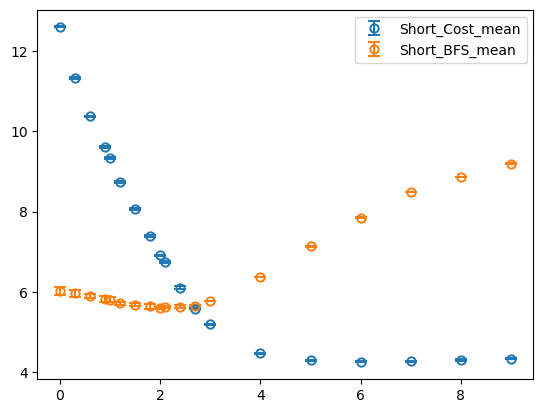

In [15]:
N_values = np.sort(df["N"].unique())
N = 131072
#alpha_a_values = []
m0, alpha_g = 2, 2
dim = 4
props = ["Short_Cost_mean",'Short_BFS_mean']
props_err = ["Short_BFS_error", "Short_Cost_error"]

for prop_err, prop in zip(props_err, props):
    df_sub = df[(df['N']==N) & (df['m0']==m0) & (df['m0']==m0) & (df['alpha_g']==alpha_g) & (df['dim']==dim)]
    
    x = df_sub['alpha_a']
    y = df_sub[prop]
    y_err = df_sub[prop_err]
    
    plt.errorbar(x=x, y=y, yerr=y_err,ls='None',marker='o',mfc='None',capsize=4,mew=1.4, label=prop)
    #plt.plot(x,y,'o',label=prop)
plt.legend()
plt.show()

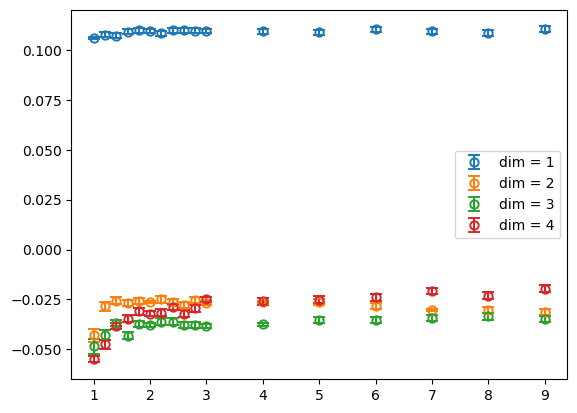

In [25]:
N_values = np.sort(df["N"].unique())
N = 131072
#alpha_a_values = []
m0, alpha_a = 2, 2
dim_lst = [1,2,3, 4]

for dim in dim_lst:
    df_sub = df[(df['N']==N) & (df['m0']==m0) & (df['m0']==m0) & (df['alpha_a']==alpha_a) & (df['dim']==dim)]
    
    x = df_sub['alpha_g']
    y = df_sub['R_Newman_mean']
    y_err = df_sub['R_Spearman_error']
    plt.errorbar(x=x, y=y, yerr=y_err,ls='None',marker='o',mfc='None',capsize=4,mew=1.4, label=f'dim = {dim}')
plt.legend()
plt.show()

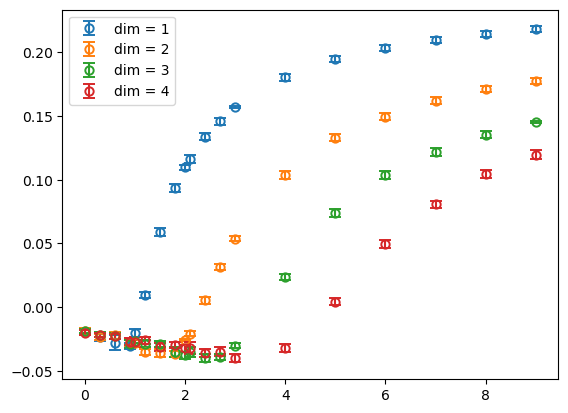

In [28]:
N_values = np.sort(df["N"].unique())
N = 131072
#alpha_a_values = []
m0, alpha_g = 2, 2
dim_lst = [1,2,3, 4]

for dim in dim_lst:
    df_sub = df[(df['N']==N) & (df['m0']==m0) & (df['m0']==m0) & (df['alpha_g']==alpha_g) & (df['dim']==dim)]
    
    x = df_sub['alpha_a']
    y = df_sub['R_Newman_mean']
    y_err = df_sub['R_Newman_error']
    plt.errorbar(x=x, y=y, yerr=y_err,ls='None',marker='o',mfc='None',capsize=4,mew=1.4, label=f'dim = {dim}')
plt.legend()
plt.show()